In [ ]:
# Weather Forecasting ML System

## 1. Dataset Loading and Initial Inspection

This notebook contains the data preparation, exploratory data analysis,
machine learning model training, evaluation, and weather prediction
for the Weather Forecasting ML System.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../data/weather_data.csv", skiprows=2)

df.head()

,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
0,2021-01-01T00:00,16.7,76.0,0.0,0.0,1007.3,0.0,8.1
1,2021-01-01T01:00,16.2,77.0,0.0,0.0,1007.0,0.0,7.6
2,2021-01-01T02:00,16.2,75.0,0.0,0.0,1006.3,0.0,9.5
3,2021-01-01T03:00,16.0,74.0,0.0,0.0,1005.9,0.0,9.4
4,2021-01-01T04:00,15.8,74.0,0.0,0.0,1005.8,0.0,9.2


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45651 entries, 0 to 45650
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   time                      45651 non-null  object 
 1   temperature_2m (°C)       45651 non-null  object 
 2   relative_humidity_2m (%)  43824 non-null  float64
 3   precipitation (mm)        43824 non-null  float64
 4   weather_code (wmo code)   43824 non-null  float64
 5   surface_pressure (hPa)    43824 non-null  float64
 6   cloud_cover (%)           43824 non-null  float64
 7   wind_speed_10m (km/h)     43824 non-null  float64
dtypes: float64(6), object(2)
memory usage: 2.8+ MB


In [6]:
df["time"] = pd.to_datetime(df["time"], format="mixed")
df["temperature_2m (°C)"] = pd.to_numeric(df["temperature_2m (°C)"], errors="coerce")

df.info()

DateParseError: Unknown datetime string format, unable to parse: time, at position 43824

In [7]:
df.tail(10)

,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
45641,2025-12-22,3,NaN,NaN,NaN,NaN,NaN,NaN
45642,2025-12-23,1,NaN,NaN,NaN,NaN,NaN,NaN
45643,2025-12-24,0,NaN,NaN,NaN,NaN,NaN,NaN
45644,2025-12-25,0,NaN,NaN,NaN,NaN,NaN,NaN
45645,2025-12-26,0,NaN,NaN,NaN,NaN,NaN,NaN
45646,2025-12-27,0,NaN,NaN,NaN,NaN,NaN,NaN
45647,2025-12-28,0,NaN,NaN,NaN,NaN,NaN,NaN
45648,2025-12-29,1,NaN,NaN,NaN,NaN,NaN,NaN
45649,2025-12-30,0,NaN,NaN,NaN,NaN,NaN,NaN
45650,2025-12-31,2,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
df["time"].tail(10)

45641    2025-12-22
45642    2025-12-23
45643    2025-12-24
45644    2025-12-25
45645    2025-12-26
45646    2025-12-27
45647    2025-12-28
45648    2025-12-29
45649    2025-12-30
45650    2025-12-31
Name: time, dtype: object

In [9]:
df = df[df["relative_humidity_2m (%)"].notna()].copy()

df.shape

(43824, 8)

In [10]:
df["time"] = pd.to_datetime(df["time"])
df["temperature_2m (°C)"] = pd.to_numeric(
    df["temperature_2m (°C)"], errors="coerce"
)

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 43824 entries, 0 to 43823
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   time                      43824 non-null  datetime64[ns]
 1   temperature_2m (°C)       43824 non-null  float64       
 2   relative_humidity_2m (%)  43824 non-null  float64       
 3   precipitation (mm)        43824 non-null  float64       
 4   weather_code (wmo code)   43824 non-null  float64       
 5   surface_pressure (hPa)    43824 non-null  float64       
 6   cloud_cover (%)           43824 non-null  float64       
 7   wind_speed_10m (km/h)     43824 non-null  float64       
dtypes: datetime64[ns](1), float64(7)
memory usage: 3.0 MB


In [11]:
df.describe()

,time,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),weather_code (wmo code),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h)
count,43824,43824.00000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000,43824.000000
mean,2023-07-02 23:30:00,27.71148,54.664590,0.122796,7.515334,1002.253553,35.753058,9.950119
min,2021-01-01 00:00:00,8.00000,4.000000,0.000000,0.000000,978.600000,0.000000,0.000000
25%,2022-04-02 11:45:00,24.60000,34.000000,0.000000,0.000000,997.900000,0.000000,7.100000
50%,2023-07-02 23:30:00,27.70000,55.000000,0.000000,0.000000,1002.300000,8.000000,9.300000
75%,2024-10-01 11:15:00,31.20000,75.000000,0.000000,3.000000,1006.900000,92.000000,12.300000
max,2025-12-31 23:00:00,46.50000,100.000000,51.700000,65.000000,1015.900000,100.000000,57.500000
std,NaN,5.93291,24.538095,0.845625,17.674370,5.546110,42.664211,4.363746


In [12]:
df.isnull().sum()

time                        0
temperature_2m (°C)         0
relative_humidity_2m (%)    0
precipitation (mm)          0
weather_code (wmo code)     0
surface_pressure (hPa)      0
cloud_cover (%)             0
wind_speed_10m (km/h)       0
dtype: int64

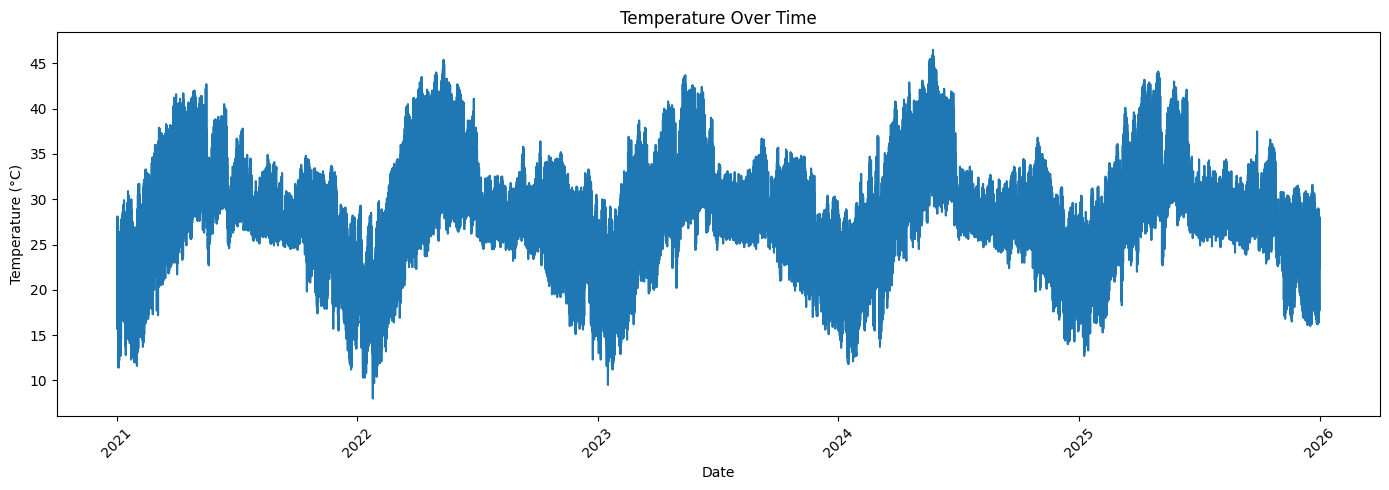

In [13]:
plt.figure(figsize=(14, 5))

plt.plot(df["time"], df["temperature_2m (°C)"])

plt.title("Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

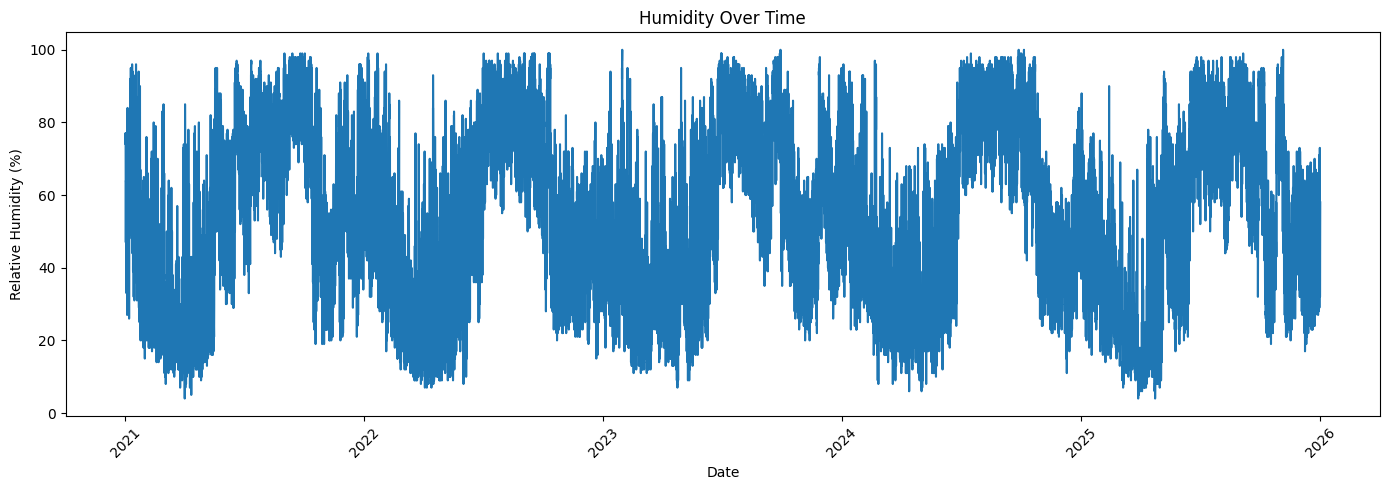

In [14]:
plt.figure(figsize=(14, 5))

plt.plot(df["time"], df["relative_humidity_2m (%)"])

plt.title("Humidity Over Time")
plt.xlabel("Date")
plt.ylabel("Relative Humidity (%)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

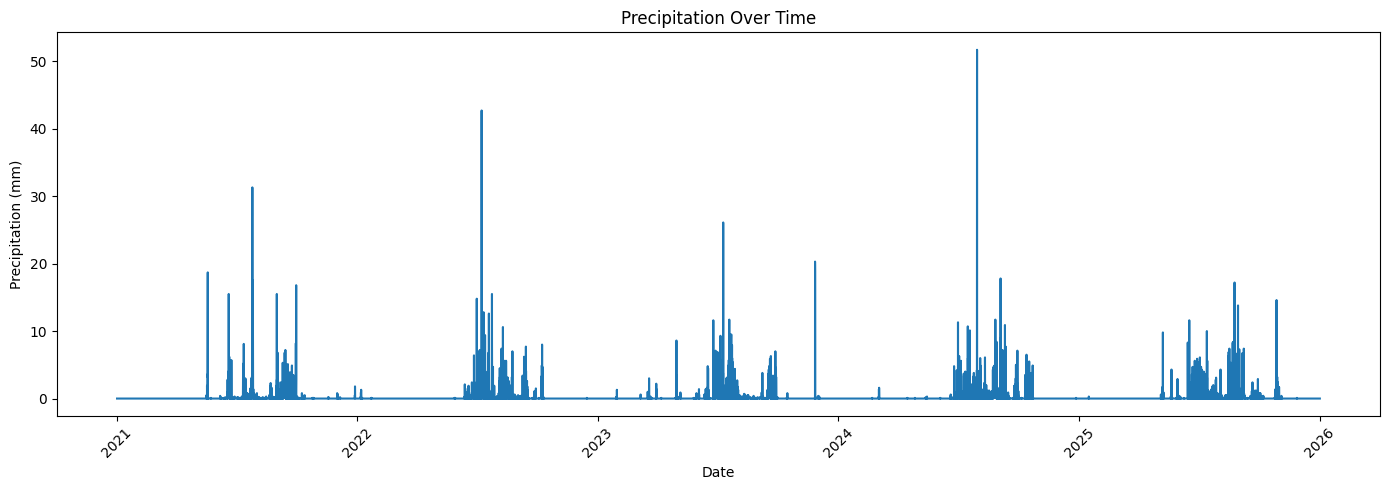

In [15]:
plt.figure(figsize=(14, 5))

plt.plot(df["time"], df["precipitation (mm)"])

plt.title("Precipitation Over Time")
plt.xlabel("Date")
plt.ylabel("Precipitation (mm)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [16]:
df["weather_code (wmo code)"].value_counts().sort_index()

weather_code (wmo code)
0.0     24875
1.0      3312
2.0      2019
3.0      8065
51.0     3582
53.0      654
55.0      209
61.0      507
63.0      512
65.0       89
Name: count, dtype: int64

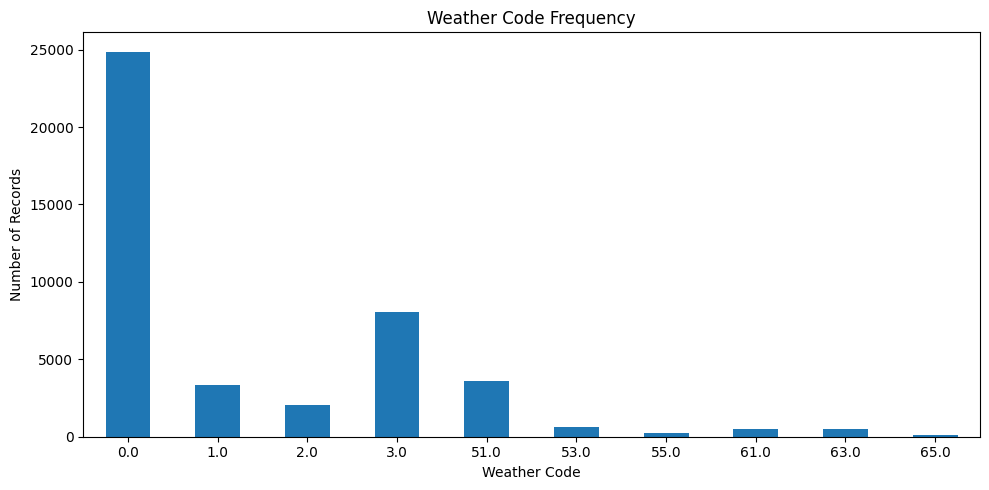

In [17]:
plt.figure(figsize=(10, 5))

df["weather_code (wmo code)"].value_counts().sort_index().plot(kind="bar")

plt.title("Weather Code Frequency")
plt.xlabel("Weather Code")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [18]:
weather_mapping = {
    0: "Clear",
    1: "Mainly Clear",
    2: "Partly Cloudy",
    3: "Overcast",
    51: "Drizzle",
    53: "Drizzle",
    55: "Drizzle",
    61: "Rain",
    63: "Rain",
    65: "Rain"
}

df["weather_condition"] = df["weather_code (wmo code)"].map(weather_mapping)

df[["weather_code (wmo code)", "weather_condition"]].drop_duplicates().sort_values(
    "weather_code (wmo code)"
)

,weather_code (wmo code),weather_condition
0,0.0,Clear
17,1.0,Mainly Clear
30,2.0,Partly Cloudy
34,3.0,Overcast
3258,51.0,Drizzle
3259,53.0,Drizzle
4027,55.0,Drizzle
3278,61.0,Rain
3293,63.0,Rain
3302,65.0,Rain


In [19]:
df["weather_condition"].value_counts()

weather_condition
Clear            24875
Overcast          8065
Drizzle           4445
Mainly Clear      3312
Partly Cloudy     2019
Rain              1108
Name: count, dtype: int64

In [20]:
daily_df = df.copy()

daily_df["date"] = daily_df["time"].dt.date

daily_df = daily_df.groupby("date").agg({
    "temperature_2m (°C)": "mean",
    "relative_humidity_2m (%)": "mean",
    "precipitation (mm)": "sum",
    "surface_pressure (hPa)": "mean",
    "cloud_cover (%)": "mean",
    "wind_speed_10m (km/h)": "mean",
    "weather_condition": lambda x: x.mode()[0]
}).reset_index()

daily_df.head()

,date,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition
0,2021-01-01,21.162500,62.708333,0.0,1006.520833,7.250000,7.962500,Clear
1,2021-01-02,20.400000,48.250000,0.0,1006.800000,35.500000,9.066667,Clear
2,2021-01-03,18.283333,45.083333,0.0,1006.045833,3.916667,7.791667,Clear
3,2021-01-04,19.433333,54.041667,0.0,1005.512500,11.250000,6.287500,Clear
4,2021-01-05,19.558333,51.125000,0.0,1007.120833,3.083333,8.929167,Clear


In [21]:
daily_df.shape

(1826, 8)

In [22]:
daily_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1826 entries, 0 to 1825
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   date                      1826 non-null   object 
 1   temperature_2m (°C)       1826 non-null   float64
 2   relative_humidity_2m (%)  1826 non-null   float64
 3   precipitation (mm)        1826 non-null   float64
 4   surface_pressure (hPa)    1826 non-null   float64
 5   cloud_cover (%)           1826 non-null   float64
 6   wind_speed_10m (km/h)     1826 non-null   float64
 7   weather_condition         1826 non-null   object 
dtypes: float64(6), object(2)
memory usage: 114.3+ KB


In [23]:
daily_df["date"] = pd.to_datetime(daily_df["date"])

daily_df["tomorrow_weather"] = daily_df["weather_condition"].shift(-1)

daily_df.head()

,date,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition,tomorrow_weather
0,2021-01-01,21.162500,62.708333,0.0,1006.520833,7.250000,7.962500,Clear,Clear
1,2021-01-02,20.400000,48.250000,0.0,1006.800000,35.500000,9.066667,Clear,Clear
2,2021-01-03,18.283333,45.083333,0.0,1006.045833,3.916667,7.791667,Clear,Clear
3,2021-01-04,19.433333,54.041667,0.0,1005.512500,11.250000,6.287500,Clear,Clear
4,2021-01-05,19.558333,51.125000,0.0,1007.120833,3.083333,8.929167,Clear,Clear


In [24]:
daily_df["tomorrow_weather"].value_counts()

tomorrow_weather
Clear            1177
Overcast          376
Drizzle           202
Mainly Clear       41
Rain               20
Partly Cloudy       9
Name: count, dtype: int64

In [25]:
target_mapping = {
    "Clear": "Clear",
    "Mainly Clear": "Clear",
    "Partly Cloudy": "Cloudy",
    "Overcast": "Cloudy",
    "Drizzle": "Rainy",
    "Rain": "Rainy"
}

daily_df["tomorrow_weather_class"] = daily_df["tomorrow_weather"].map(target_mapping)

daily_df["tomorrow_weather_class"].value_counts()

tomorrow_weather_class
Clear     1218
Cloudy     385
Rainy      222
Name: count, dtype: int64

In [26]:
daily_df = daily_df.dropna(subset=["tomorrow_weather_class"]).copy()

daily_df.shape

(1825, 10)

In [29]:
daily_df.to_csv("../data/daily_weather_dataset.csv", index=False)

In [30]:
daily_df["month"] = daily_df["date"].dt.month

X = daily_df[
    [
        "temperature_2m (°C)",
        "relative_humidity_2m (%)",
        "precipitation (mm)",
        "surface_pressure (hPa)",
        "cloud_cover (%)",
        "wind_speed_10m (km/h)",
        "weather_condition",
        "month"
    ]
]

y = daily_df["tomorrow_weather_class"]

X.head()

,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition,month
0,21.162500,62.708333,0.0,1006.520833,7.250000,7.962500,Clear,1
1,20.400000,48.250000,0.0,1006.800000,35.500000,9.066667,Clear,1
2,18.283333,45.083333,0.0,1006.045833,3.916667,7.791667,Clear,1
3,19.433333,54.041667,0.0,1005.512500,11.250000,6.287500,Clear,1
4,19.558333,51.125000,0.0,1007.120833,3.083333,8.929167,Clear,1


In [31]:
split_index = int(len(X) * 0.8)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Training period:", daily_df["date"].iloc[0], "to", daily_df["date"].iloc[split_index - 1])
print("Testing period:", daily_df["date"].iloc[split_index], "to", daily_df["date"].iloc[-1])

Training samples: 1460
Testing samples: 365
Training period: 2021-01-01 00:00:00 to 2024-12-30 00:00:00
Testing period: 2024-12-31 00:00:00 to 2025-12-30 00:00:00


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    "temperature_2m (°C)",
    "relative_humidity_2m (%)",
    "precipitation (mm)",
    "surface_pressure (hPa)",
    "cloud_cover (%)",
    "wind_speed_10m (km/h)",
    "month"
]

categorical_features = ["weather_condition"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully.")

Preprocessor created successfully.


In [33]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("All 3 models created successfully.")

All 3 models created successfully.


In [34]:
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])
    
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

print("All 3 models trained successfully.")

All 3 models trained successfully.


In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.775342,0.770059,0.775342,0.768496
1,Decision Tree,0.687671,0.717363,0.687671,0.700192
2,Random Forest,0.794521,0.787364,0.794521,0.784718



Logistic Regression
[[223  16   1]
 [ 20  30  30]
 [  3  12  30]]


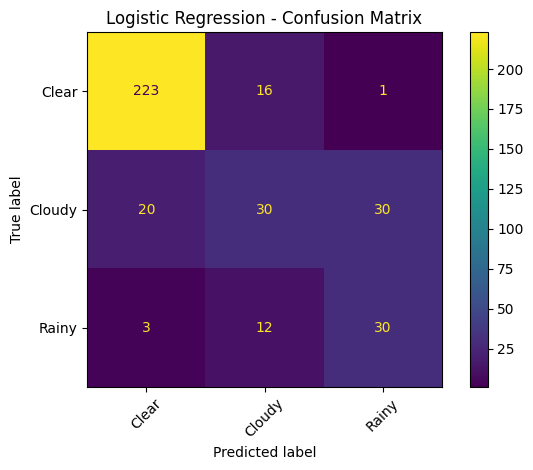


Decision Tree
[[198  41   1]
 [ 20  28  32]
 [  1  19  25]]


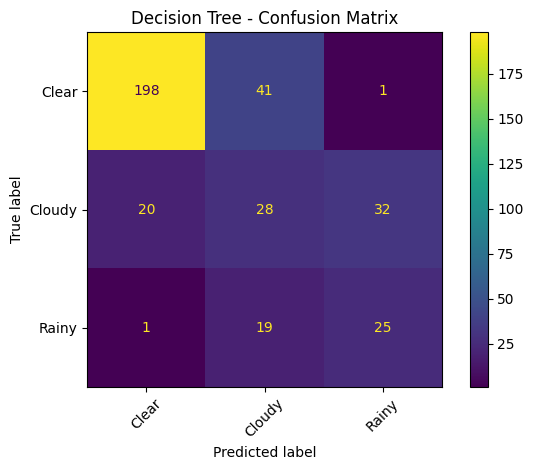


Random Forest
[[229  10   1]
 [ 20  31  29]
 [  3  12  30]]


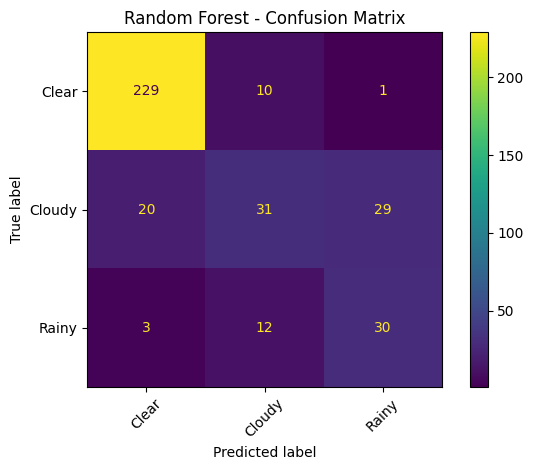

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

for name, model in trained_models.items():
    y_pred = model.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    
    print(f"\n{name}")
    print(cm)
    
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=model.classes_
    )
    
    disp.plot()
    plt.title(f"{name} - Confusion Matrix")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [37]:
import joblib

final_model = trained_models["Random Forest"]

joblib.dump(
    final_model,
    "../models/weather_random_forest.pkl"
)

print("Random Forest model saved successfully.")

Random Forest model saved successfully.


In [38]:
import requests

location = "Ahmedabad"

url = "https://geocoding-api.open-meteo.com/v1/search"

params = {
    "name": location,
    "count": 1,
    "language": "en",
    "format": "json"
}

response = requests.get(url, params=params)

response.json()

{'results': [{'id': 1279233,
   'name': 'Ahmedabad',
   'latitude': 23.02579,
   'longitude': 72.58727,
   'elevation': 56.0,
   'feature_code': 'PPL',
   'country_code': 'IN',
   'admin1_id': 1270770,
   'admin2_id': 1279234,
   'admin3_id': 12684092,
   'timezone': 'Asia/Kolkata',
   'population': 6357693,
   'country_id': 1269750,
   'country': 'India',
   'admin1': 'Gujarat',
   'admin2': 'Ahmadābād District',
   'admin3': 'Sabarmati'}],
 'generationtime_ms': 0.42176247}

In [39]:
# Get today's weather data for the selected location

latitude = response.json()["results"][0]["latitude"]
longitude = response.json()["results"][0]["longitude"]

weather_url = "https://api.open-meteo.com/v1/forecast"

weather_params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "weather_code",
        "surface_pressure",
        "cloud_cover",
        "wind_speed_10m"
    ],
    "forecast_days": 1,
    "timezone": "auto"
}

weather_response = requests.get(weather_url, params=weather_params)

weather_response.json()

{'latitude': 23.022846,
 'longitude': 72.60188,
 'generationtime_ms': 0.19824504852294922,
 'utc_offset_seconds': 19800,
 'timezone': 'Asia/Kolkata',
 'timezone_abbreviation': 'GMT+5:30',
 'elevation': 53.0,
 'hourly_units': {'time': 'iso8601',
  'temperature_2m': '°C',
  'relative_humidity_2m': '%',
  'precipitation': 'mm',
  'weather_code': 'wmo code',
  'surface_pressure': 'hPa',
  'cloud_cover': '%',
  'wind_speed_10m': 'km/h'},
 'hourly': {'time': ['2026-09-27T00:00',
   '2026-09-27T01:00',
   '2026-09-27T02:00',
   '2026-09-27T03:00',
   '2026-09-27T04:00',
   '2026-09-27T05:00',
   '2026-09-27T06:00',
   '2026-09-27T07:00',
   '2026-09-27T08:00',
   '2026-09-27T09:00',
   '2026-09-27T10:00',
   '2026-09-27T11:00',
   '2026-09-27T12:00',
   '2026-09-27T13:00',
   '2026-09-27T14:00',
   '2026-09-27T15:00',
   '2026-09-27T16:00',
   '2026-09-27T17:00',
   '2026-09-27T18:00',
   '2026-09-27T19:00',
   '2026-09-27T20:00',
   '2026-09-27T21:00',
   '2026-09-27T22:00',
   '2026-09-27T2

In [40]:
import pandas as pd

# Get hourly weather data
hourly_data = weather_response.json()["hourly"]

# Create DataFrame
today_df = pd.DataFrame(hourly_data)

# Convert time column to datetime
today_df["time"] = pd.to_datetime(today_df["time"])

# Calculate today's daily weather features
today_features = pd.DataFrame({
    "temperature_2m (°C)": [today_df["temperature_2m"].mean()],
    "relative_humidity_2m (%)": [today_df["relative_humidity_2m"].mean()],
    "precipitation (mm)": [today_df["precipitation"].sum()],
    "surface_pressure (hPa)": [today_df["surface_pressure"].mean()],
    "cloud_cover (%)": [today_df["cloud_cover"].mean()],
    "wind_speed_10m (km/h)": [today_df["wind_speed_10m"].mean()]
})

# Convert weather codes into our training conditions
def weather_condition(code):
    if code == 0:
        return "Clear"
    elif code == 1:
        return "Mainly Clear"
    elif code == 2:
        return "Partly Cloudy"
    elif code == 3:
        return "Overcast"
    elif code in [51, 53, 55]:
        return "Drizzle"
    elif code in [61, 63, 65]:
        return "Rain"
    else:
        return "Clear"

# Find the most common weather condition today
today_conditions = today_df["weather_code"].apply(weather_condition)
today_features["weather_condition"] = today_conditions.mode()[0]

# Add month
today_features["month"] = today_df["time"].dt.month.iloc[0]

today_features

,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition,month
0,29.141667,67.541667,0.0,1002.1125,39.375,10.633333,Mainly Clear,9


In [41]:
import joblib

# Load the trained Random Forest model
final_model = joblib.load("../models/weather_random_forest.pkl")

print("Random Forest model loaded successfully.")

Random Forest model loaded successfully.


In [42]:
# Predict tomorrow's weather condition

prediction = final_model.predict(today_features)

print("Predicted weather for tomorrow:", prediction[0])

Predicted weather for tomorrow: Clear


In [43]:
# Get prediction probabilities

probabilities = final_model.predict_proba(today_features)

confidence = probabilities.max() * 100

print("Predicted weather for tomorrow:", prediction[0])
print("Prediction confidence:", round(confidence, 2), "%")

Predicted weather for tomorrow: Clear
Prediction confidence: 62.0 %


In [44]:
# Test user location input

user_location = input("Enter location: ")

print("Selected location:", user_location)


Enter location:  Mumbai


Selected location: Mumbai


In [45]:
# Convert user location into latitude and longitude

geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"

geocoding_params = {
    "name": user_location,
    "count": 1,
    "language": "en",
    "format": "json"
}

geocoding_response = requests.get(
    geocoding_url,
    params=geocoding_params
)

location_data = geocoding_response.json()

latitude = location_data["results"][0]["latitude"]
longitude = location_data["results"][0]["longitude"]

print("Location:", location_data["results"][0]["name"])
print("Latitude:", latitude)
print("Longitude:", longitude)

Location: Mumbai
Latitude: 19.07283
Longitude: 72.88261


In [46]:
# Get today's weather for the user's location

weather_url = "https://api.open-meteo.com/v1/forecast"

weather_params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": [
        "temperature_2m",
        "relative_humidity_2m",
        "precipitation",
        "weather_code",
        "surface_pressure",
        "cloud_cover",
        "wind_speed_10m"
    ],
    "forecast_days": 1,
    "timezone": "auto"
}

weather_response = requests.get(
    weather_url,
    params=weather_params
)

print("Weather data received successfully.")

Weather data received successfully.


In [47]:
# Convert hourly weather data into daily features

hourly_data = weather_response.json()["hourly"]

today_df = pd.DataFrame(hourly_data)

today_df["time"] = pd.to_datetime(today_df["time"])


today_features = pd.DataFrame({
    "temperature_2m (°C)": [today_df["temperature_2m"].mean()],
    "relative_humidity_2m (%)": [today_df["relative_humidity_2m"].mean()],
    "precipitation (mm)": [today_df["precipitation"].sum()],
    "surface_pressure (hPa)": [today_df["surface_pressure"].mean()],
    "cloud_cover (%)": [today_df["cloud_cover"].mean()],
    "wind_speed_10m (km/h)": [today_df["wind_speed_10m"].mean()]
})


today_conditions = today_df["weather_code"].apply(weather_condition)

today_features["weather_condition"] = today_conditions.mode()[0]

today_features["month"] = today_df["time"].dt.month.iloc[0]


today_features

,temperature_2m (°C),relative_humidity_2m (%),precipitation (mm),surface_pressure (hPa),cloud_cover (%),wind_speed_10m (km/h),weather_condition,month
0,28.6,70.791667,0.1,1009.266667,44.416667,5.804167,Mainly Clear,9


In [48]:
# Predict tomorrow's weather for the selected location

prediction = final_model.predict(today_features)

probabilities = final_model.predict_proba(today_features)

confidence = probabilities.max() * 100

print("Location:", location_data["results"][0]["name"])
print("Predicted weather for tomorrow:", prediction[0])
print("Prediction confidence:", round(confidence, 2), "%")

Location: Mumbai
Predicted weather for tomorrow: Clear
Prediction confidence: 67.0 %


In [51]:
def predict_weather(location):

    # 1. Convert location to coordinates
    geocoding_url = "https://geocoding-api.open-meteo.com/v1/search"

    geocoding_params = {
        "name": location,
        "count": 1,
        "language": "en",
        "format": "json"
    }

    geocoding_response = requests.get(
        geocoding_url,
        params=geocoding_params
    )

    location_data = geocoding_response.json()

    if "results" not in location_data:
        print("Location not found.")
        return

    latitude = location_data["results"][0]["latitude"]
    longitude = location_data["results"][0]["longitude"]
    location_name = location_data["results"][0]["name"]


    # 2. Get today's weather
    weather_url = "https://api.open-meteo.com/v1/forecast"

    weather_params = {
        "latitude": latitude,
        "longitude": longitude,
        "hourly": [
            "temperature_2m",
            "relative_humidity_2m",
            "precipitation",
            "weather_code",
            "surface_pressure",
            "cloud_cover",
            "wind_speed_10m"
        ],
        "forecast_days": 1,
        "timezone": "auto"
    }

    weather_response = requests.get(
        weather_url,
        params=weather_params
    )

    hourly_data = weather_response.json()["hourly"]


    # 3. Convert hourly data to daily features
    today_df = pd.DataFrame(hourly_data)

    today_df["time"] = pd.to_datetime(today_df["time"])

    today_features = pd.DataFrame({
        "temperature_2m (°C)": [today_df["temperature_2m"].mean()],
        "relative_humidity_2m (%)": [today_df["relative_humidity_2m"].mean()],
        "precipitation (mm)": [today_df["precipitation"].sum()],
        "surface_pressure (hPa)": [today_df["surface_pressure"].mean()],
        "cloud_cover (%)": [today_df["cloud_cover"].mean()],
        "wind_speed_10m (km/h)": [today_df["wind_speed_10m"].mean()]
    })

    today_conditions = today_df["weather_code"].apply(weather_condition)

    today_features["weather_condition"] = today_conditions.mode()[0]

    today_features["month"] = today_df["time"].dt.month.iloc[0]


    # 4. Make prediction
    prediction = final_model.predict(today_features)

    probabilities = final_model.predict_proba(today_features)

    confidence = probabilities.max() * 100


    # 5. Display result
    print("Location:", location_name)
    print("Predicted weather for tomorrow:", prediction[0])
    print("Prediction confidence:", round(confidence, 2), "%")

In [52]:
predict_weather("Pune")

Location: Pune
Predicted weather for tomorrow: Clear
Prediction confidence: 75.0 %


In [53]:
predict_weather("XYZ12345")

Location not found.
